In [1]:
"""
Load the model-comparison export (checkpoints/final_runs_cv + checkpoints/final_runs_single
+ checkpoints/final_runs_nosplitted) into the {label: {metric: [k=3,5,10 values]}} shape
the plotting cells below expect, for the 5-fold CV numbers, the single train/test-split
numbers, and the no-split (100% train = 100% eval) numbers.

Regenerate model_comparison.csv from the checkpoints with:
    python ../scripts/export_comparison.py   (see repo docs / ask Claude)
"""

import csv
from collections import defaultdict
from pathlib import Path

COMPARISON_CSV = Path("model_comparison.csv")
K_VALUES = [3, 5, 10]


def load_split(csv_path: Path, split: str) -> dict:
    """label -> metric -> [value@k=3, value@k=5, value@k=10]"""
    nested = defaultdict(lambda: defaultdict(dict))
    with open(csv_path) as f:
        for row in csv.DictReader(f):
            if row["split"] != split or row["metric"] == "auc":
                continue
            nested[row["label"]][row["metric"]][int(row["k"])] = float(row["value"])
    return {
        label: {metric: [per_k[k] for k in K_VALUES] for metric, per_k in metrics.items()}
        for label, metrics in nested.items()
    }


cv_data = load_split(COMPARISON_CSV, "cv")
single_data = load_split(COMPARISON_CSV, "single")
nosplit_data = load_split(COMPARISON_CSV, "nosplit")

print("CV (5-fold) mean metrics:")
for label, m in cv_data.items():
    print(f"  {label}: {m}")
print("\nSingle train/test-split (best checkpoint) metrics:")
for label, m in single_data.items():
    print(f"  {label}: {m}")
print("\nNo-split (100% train = 100% eval, best checkpoint) metrics:")
for label, m in nosplit_data.items():
    print(f"  {label}: {m}")


CV (5-fold) mean metrics:
  GHCF-R: {'precision': [0.4238095238095238, 0.4047619047619048, 0.4014285714285714], 'recall': [0.12779989828635147, 0.19337217179828017, 0.33224186062979166], 'ndcg': [0.6998952427418107, 0.737784523422196, 0.7314882287897689], 'hit': [0.8428571428571429, 0.9380952380952381, 0.9714285714285715]}
  GHCF-A: {'precision': [0.42539682539682533, 0.42000000000000004, 0.41047619047619044], 'recall': [0.1272353147217679, 0.19030315141891496, 0.3471582780930072], 'ndcg': [0.6215956026037899, 0.6797692037130529, 0.6923625507122996], 'hit': [0.819047619047619, 0.9380952380952381, 1.0]}
  GHCF-CE: {'precision': [0.5158730158730158, 0.5057142857142857, 0.48904761904761906], 'recall': [0.12846839698595844, 0.19161462251497924, 0.32799932822964234], 'ndcg': [0.7690328972147775, 0.7589510717950846, 0.7794167631995634], 'hit': [0.9380952380952381, 0.9380952380952381, 1.0]}

Single train/test-split (best checkpoint) metrics:
  GHCF-R: {'precision': [0.22222222222222218, 0.173

In [2]:
"""
Publication-style figure: Precision@k, Recall@k, nDCG@k, HR@k for the
GHCF-R / GHCF-A / GHCF-CE comparison (norm-adjacency GCN backbone, mse loss),
one row of 4 subplots, sized and styled for a research-paper figure.

GHCF-R   = RATING-only baseline            (single_none_mse_norm_gcn)
GHCF-A   = all-relations baseline          (default_none_mse_norm_gcn)
GHCF-CE  = all-relations + causal SEM head (default_causal_fs0_mse_norm_gcn)

make_figure() is shared by the two cells below: one renders the 5-fold CV
comparison (recommendation_metrics.*, the paper figure -- fixed ylims kept
byte-for-byte identical to the original hardcoded version), the other the
single train/test-split comparison (recommendation_metrics_single.*, auto ylims).
"""

import matplotlib.pyplot as plt

K_VALUES = [3, 5, 10]

METRICS = [
    ("precision", r"Precision@$k$"),
    ("recall", r"Recall@$k$"),
    ("ndcg", r"nDCG@$k$"),
    ("hit", r"HR@$k$"),
]

STYLES = {
    "GHCF-R": {"marker": "o", "linewidth": 1.7, "alpha": 0.72},
    "GHCF-A": {"marker": "D", "linewidth": 1.7, "alpha": 0.72},
    "GHCF-CE": {"marker": "^", "linewidth": 2.2, "alpha": 1.00},
}

plt.rcParams.update(
    {
        "font.family": "DejaVu Sans",
        "font.size": 10,
        "axes.titlesize": 12,
        "axes.labelsize": 10,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "legend.fontsize": 10,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)


def _auto_ylims(data, pad_frac=0.08):
    ylims = {}
    for metric, _ in METRICS:
        vals = [v for m in data.values() for v in m[metric]]
        lo, hi = min(vals), max(vals)
        pad = (hi - lo) * pad_frac or 0.02
        ylims[metric] = (max(0.0, lo - pad), min(1.02, hi + pad))
    return ylims


def make_figure(data: dict, out_prefix: str, ylims: dict | None = None, k=K_VALUES):
    """Render + save the 2x2 metrics-vs-k figure for ``data`` (see load_split above)."""
    if ylims is None:
        ylims = _auto_ylims(data)

    fig, axes = plt.subplots(2, 2, figsize=(11.5, 6.6), sharex=True, constrained_layout=False)
    plt.subplots_adjust(hspace=0.3, wspace=0.3)

    # Delta relative to GHCF-R at k=10 (when both methods are present).
    delta = {}
    if "GHCF-R" in data and "GHCF-CE" in data:
        for metric, _ in METRICS:
            r = data["GHCF-R"][metric][-1]
            ce = data["GHCF-CE"][metric][-1]
            delta[metric] = (ce - r) / r * 100

    for ax, (metric, title) in zip(axes.flat, METRICS):
        for method, values in data.items():
            s = STYLES.get(method, {"marker": "s", "linewidth": 1.7, "alpha": 0.8})
            ax.plot(
                k,
                values[metric],
                marker=s["marker"],
                markersize=6.5 if method != "GHCF-CE" else 7.5,
                linewidth=s["linewidth"],
                alpha=s["alpha"],
                label=method,
                solid_capstyle="round",
            )

        ax.set_title(title, pad=9)
        ax.set_ylim(*ylims[metric])
        ax.set_xticks(k)
        ax.set_xlabel(r"$k$", labelpad=4)
        ax.grid(axis="y", linewidth=0.6, alpha=0.25)
        ax.grid(axis="x", visible=False)
        ax.tick_params(length=3.5)

        if "GHCF-CE" in data:
            ce_last = data["GHCF-CE"][metric][-1]
            ax.annotate(
                f"{ce_last:.3f}",
                xy=(k[-1], ce_last),
                xytext=(7, 7),
                textcoords="offset points",
                fontsize=8.5,
                fontweight="bold",
                ha="left",
                va="bottom",
            )

        if metric in delta:
            sign = "+" if delta[metric] >= 0 else "\u2212"
            ax.text(
                0.98, 0.06,
                f"{sign}{abs(delta[metric]):.1f}% vs. GHCF-R",
                transform=ax.transAxes,
                ha="right", va="bottom",
                fontsize=8.2,
            )

    for ax, label in zip(axes.flat, ["(a)", "(b)", "(c)", "(d)"]):
        ax.text(0.01, 1.02, label, transform=ax.transAxes, fontsize=10, fontweight="bold", va="bottom")

    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(
        handles, labels, loc="upper center", ncol=len(data), frameon=False,
        bbox_to_anchor=(0.5, 0.995), handlelength=2.5, columnspacing=2.0,
    )

    fig.subplots_adjust(left=0.065, right=0.985, bottom=0.105, top=0.86, wspace=0.20, hspace=0.32)

    png_path = Path(f"{out_prefix}.png")
    pdf_path = Path(f"{out_prefix}.pdf")
    svg_path = Path(f"{out_prefix}.svg")
    fig.savefig(png_path, dpi=400, bbox_inches="tight")
    fig.savefig(pdf_path, bbox_inches="tight")
    fig.savefig(svg_path, bbox_inches="tight")
    plt.show()

    print(f"PNG: {png_path}")
    print(f"PDF: {pdf_path}")
    print(f"SVG: {svg_path}")
    return fig


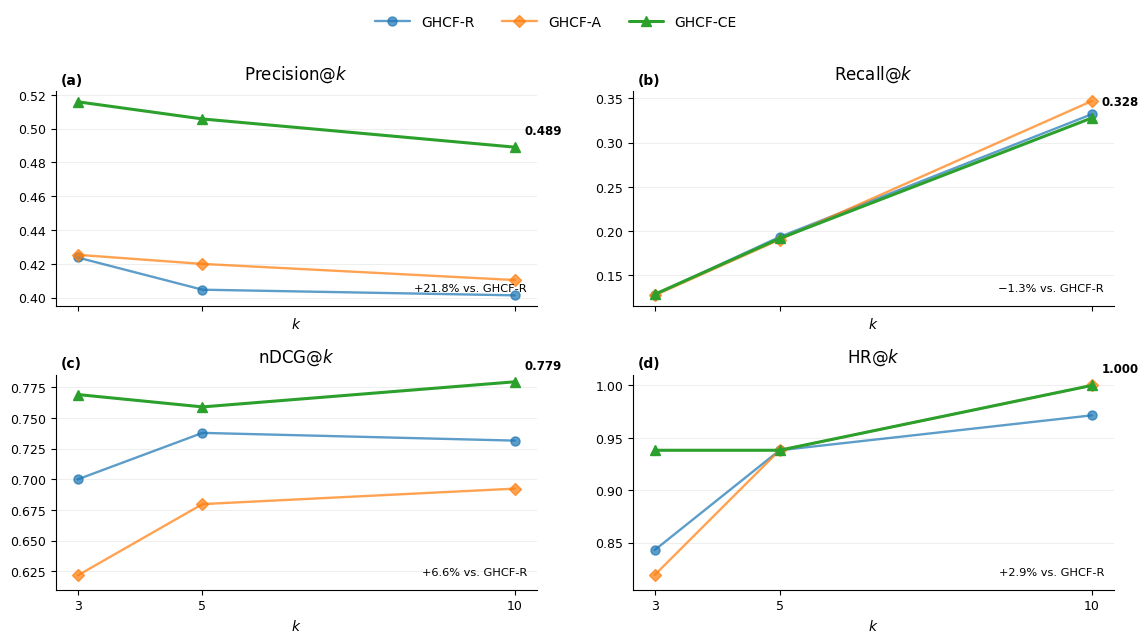

PNG: recommendation_metrics.png
PDF: recommendation_metrics.pdf
SVG: recommendation_metrics.svg


In [3]:
from pathlib import Path

# 5-fold CV comparison -- the paper figure. Fixed ylims kept identical to the
# original hardcoded version so this reproduces recommendation_metrics.* exactly
# (the underlying numbers are unchanged -- verified against
# checkpoints/final_runs_cv/*/cv_results.json).
CV_YLIMS = {
    "precision": (0.395, 0.522),
    "recall": (0.115, 0.358),
    "ndcg": (0.610, 0.785),
    "hit": (0.805, 1.010),
}

_ = make_figure(cv_data, out_prefix="recommendation_metrics", ylims=CV_YLIMS)


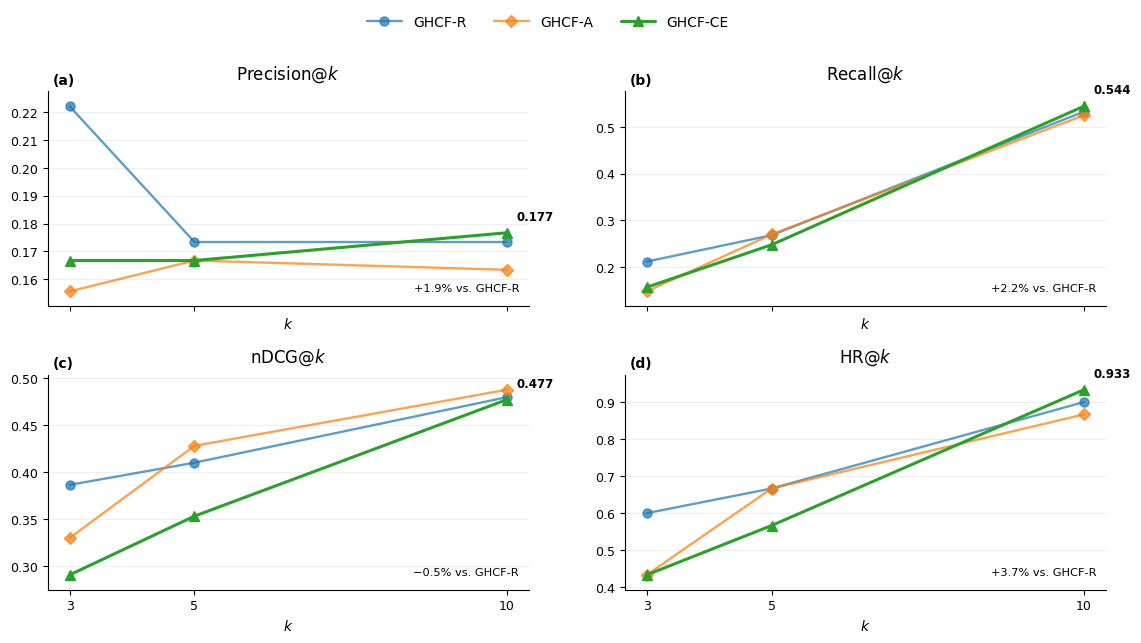

PNG: recommendation_metrics_single.png
PDF: recommendation_metrics_single.pdf
SVG: recommendation_metrics_single.svg


In [4]:
# Single train/test-split comparison (best-checkpoint metrics) -- same 3 models,
# ylims auto-scaled since the single-split numbers live on a different range
# (warm-user, per-row holdout -- see conversation notes on why single-split and
# CV numbers are not directly comparable).
_ = make_figure(single_data, out_prefix="recommendation_metrics_single")


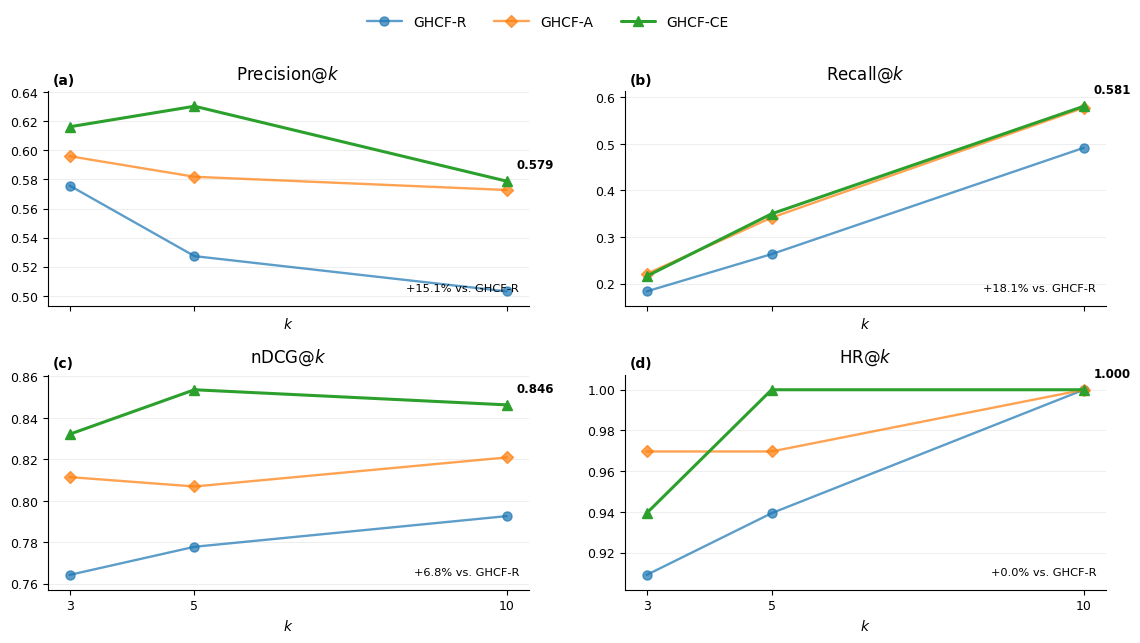

PNG: recommendation_metrics_nosplit.png
PDF: recommendation_metrics_nosplit.pdf
SVG: recommendation_metrics_nosplit.svg


In [5]:
# No-split comparison (100% of the data used for both training and evaluation,
# best-checkpoint metrics) -- same 3 models. This is a training-set fit check,
# not a generalization measure: ranking evaluation has no train-item exclusion
# since test == train here, so values run much higher than single/cv.
_ = make_figure(nosplit_data, out_prefix="recommendation_metrics_nosplit")
